# ELEC 872 Workshop (Nov 10): AffectNet baseline on FER2013 / FER+

**Before anything:** *Runtime → Change runtime type → T4 GPU*.

Every run saves to Google Drive (`MyDrive/fer_runs/<run name>/`). If Colab disconnects, **re-run the setup cells and then the same training cell**: it resumes from the last finished epoch.

**Splitting the work (two Colab sessions in parallel):**

| Partner A | Partner B |
|---|---|
| Ex 1 baseline (~15 min) | Ex 4a from scratch (~15 min) |
| Ex 2 48px ResNet (~25 min) | Ex 4b AlexNet (~10 min) |
| Ex 3 improved run (~45–60 min) | Ex 4d FaceNet (~30–40 min) |
| | Ex 4c comparison plot (needs Partner A's Ex 1 run) |
| | Ex 5 photos (uses the best run from either partner) |

Times are rough T4 estimates. Each partner runs the **Setup** cells, then only their own exercises. Both partners should save into the same shared `fer_runs` Drive folder (see PARTNER_GUIDE.md) so Ex 4c, Ex 5 and the Summary table can see every run.

Score to optimize: **test macro-F1**. Accuracy is for comparing with published papers.

## 0. Setup (run every time you open the notebook)

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
# Mount Drive (results are saved there) and get the code.
# Put fer_project.zip in the top of your Google Drive ("My Drive"); otherwise you'll be asked to upload it.
import os
from google.colab import drive
drive.mount('/content/drive')

ZIP = '/content/drive/MyDrive/fer_project.zip'
if not os.path.exists(ZIP):
    from google.colab import files
    print('fer_project.zip not found in My Drive, please upload it:')
    ZIP = '/content/' + list(files.upload())[0]
!rm -rf /content/fer_project && unzip -q -o "$ZIP" -d /content
%cd /content/fer_project

# facenet-pytorch (Exercise 4d). --no-deps so it does NOT replace Colab's PyTorch.
!pip install -q --no-deps facenet-pytorch

RUNS = '/content/drive/MyDrive/fer_runs'   # all results
DATA = '/content/data'                      # FER2013 is downloaded here (~92 MB, about 1 min)
os.makedirs(RUNS, exist_ok=True)

Mounted at /content/drive
/content/fer_project


In [6]:
# Helpers: show a run's plots, and a table of every finished run.
import glob, json
import pandas as pd
from IPython.display import Image, display

def show(run, plots=('learning_curves', 'confusion_matrix')):
    for p in plots:
        f = f'{RUNS}/{run}/plots/{p}.png'
        if os.path.exists(f):
            print(p); display(Image(f))

def results():
    rows = []
    for f in sorted(glob.glob(f'{RUNS}/*/test_results.json')):
        run_dir = os.path.dirname(f)
        r = json.load(open(f))
        h = pd.read_csv(f'{run_dir}/history.csv') if os.path.exists(f'{run_dir}/history.csv') else None
        rows.append({'run': os.path.basename(run_dir),
                     'test macro-F1': round(r['macro_f1'], 4), 'test accuracy': round(r['accuracy'], 4),
                     'best epoch': r['epoch'], 'epochs run': len(h) if h is not None else None})
    return pd.DataFrame(rows).sort_values('test macro-F1', ascending=False).reset_index(drop=True) if rows else 'no finished runs yet'

BASE = 'resnet18_ferplus_majority_128px_sqrt_inverse'

## Exercise 1: baseline (ResNet-18, ImageNet weights, 48→128 px, 25 epochs) · Partner A

In [ ]:
!python train.py --data-dir $DATA --out-dir $RUNS

Device: Tesla T4
Extracting /content/data/fer2013.tar.gz
  verified: identical to the official Kaggle fer2013.csv
Found FER2013 (csv) at /content/data/fer2013/fer2013.csv
  train:  26940 images
  val  :   3396 images
  test :   3376 images
Run folder: /content/drive/MyDrive/fer_runs/resnet18_ferplus_majority_128px_sqrt_inverse
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 138MB/s]
resnet18: 11.2M parameters
          images  loss weight
neutral     9365         0.70
happy       7410         0.78
surprise    3378         1.16
sad         3403         1.16
angry       2399         1.38
disgust      175         5.09
fear         648         2.65
contempt     162         5.30
epoch  1/25 | train loss 2.176 | val loss 1.694 | val acc 0.695 | val macro-F1 0.486 | 17s  <- best
epoch  2/25 | train loss 1.730 | val loss 1.509 | val acc 0.739 | val macro-F1 0.576 | 15s  <- best
e

learning_curves


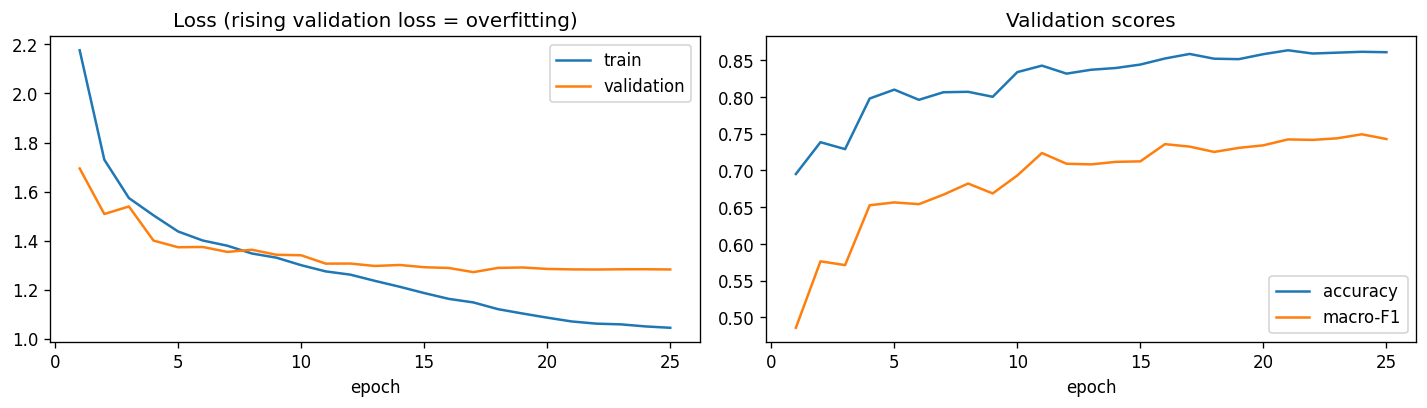

confusion_matrix


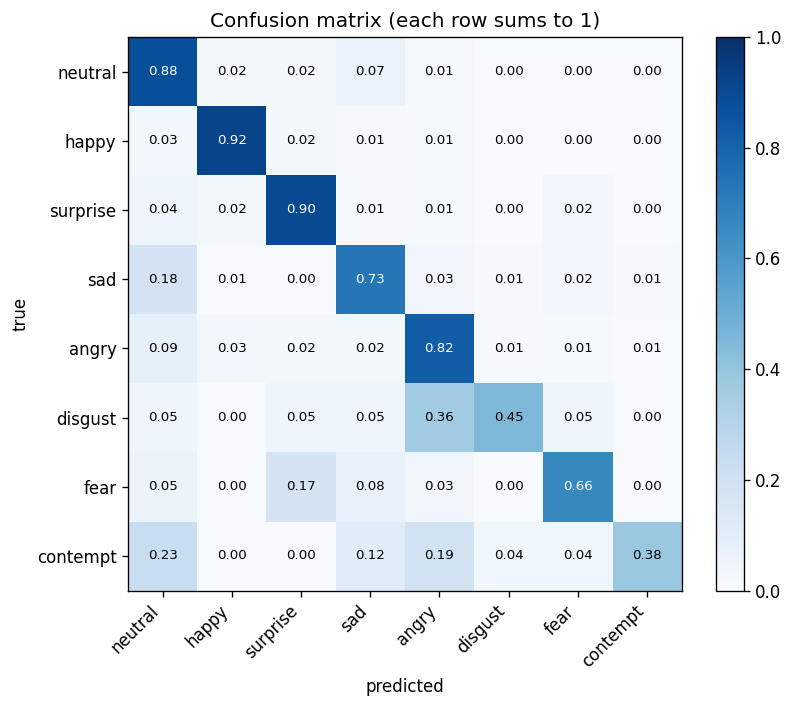

In [ ]:
show(BASE)

## Exercise 2: adapt the network to 48×48 faces instead of enlarging them · Partner A

`--model resnet18_small` (see `models.py`): the standard ResNet stem (7×7 stride-2 conv + max-pool) divides the image by 4 straight away, which is designed for 224 px ImageNet photos. On a 48 px face that leaves a 12×12 map before the first residual block and 2×2 at the end. So we:
* replace `conv1` with a **3×3, stride-1** conv (initialized from the centre 3×3 of the pretrained 7×7 filters),
* remove the **max-pool**,
* feed the **native 48×48** image (`--img-size 48`, no upscaling).

The feature maps are then 48→24→12→6, the same as CIFAR-style ResNets. All other layers keep their ImageNet weights.

In [ ]:
!python train.py --data-dir $DATA --out-dir $RUNS --model resnet18_small --img-size 48

Device: Tesla T4
Found FER2013 (csv) at /content/data/fer2013/fer2013.csv
  train:  26940 images
  val  :   3396 images
  test :   3376 images
Run folder: /content/drive/MyDrive/fer_runs/resnet18_small_ferplus_majority_48px_sqrt_inverse
resnet18_small: 11.2M parameters
          images  loss weight
neutral     9365         0.70
happy       7410         0.78
surprise    3378         1.16
sad         3403         1.16
angry       2399         1.38
disgust      175         5.09
fear         648         2.65
contempt     162         5.30
epoch  1/25 | train loss 2.155 | val loss 1.701 | val acc 0.687 | val macro-F1 0.470 | 23s  <- best
epoch  2/25 | train loss 1.740 | val loss 1.532 | val acc 0.730 | val macro-F1 0.576 | 24s  <- best
epoch  3/25 | train loss 1.589 | val loss 1.466 | val acc 0.794 | val macro-F1 0.618 | 26s  <- best
epoch  4/25 | train loss 1.511 | val loss 1.451 | val acc 0.781 | val macro-F1 0.648 | 26s  <- best
epoch  5/25 | train loss 1.445 | val loss 1.366 | val acc 0.

learning_curves


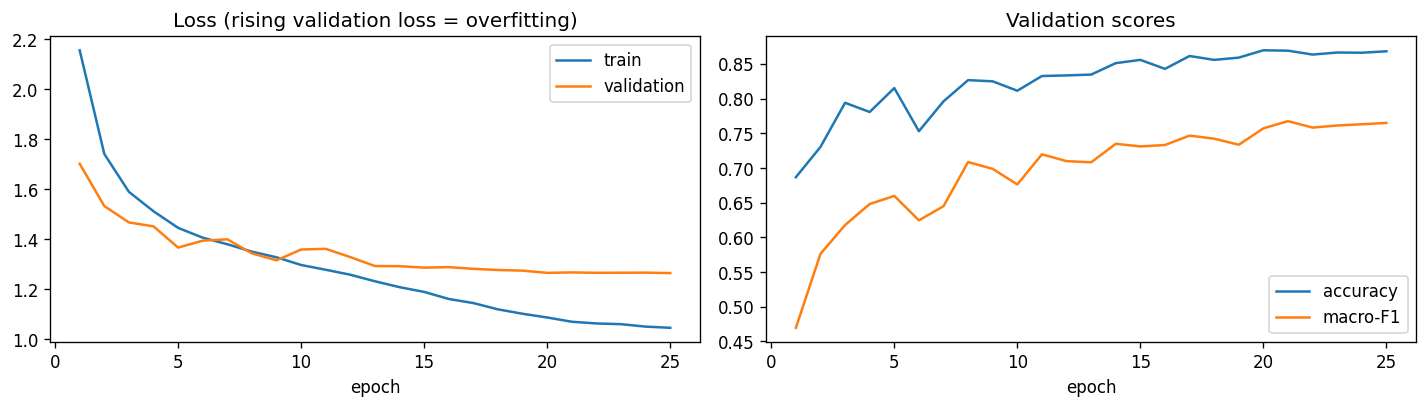

confusion_matrix


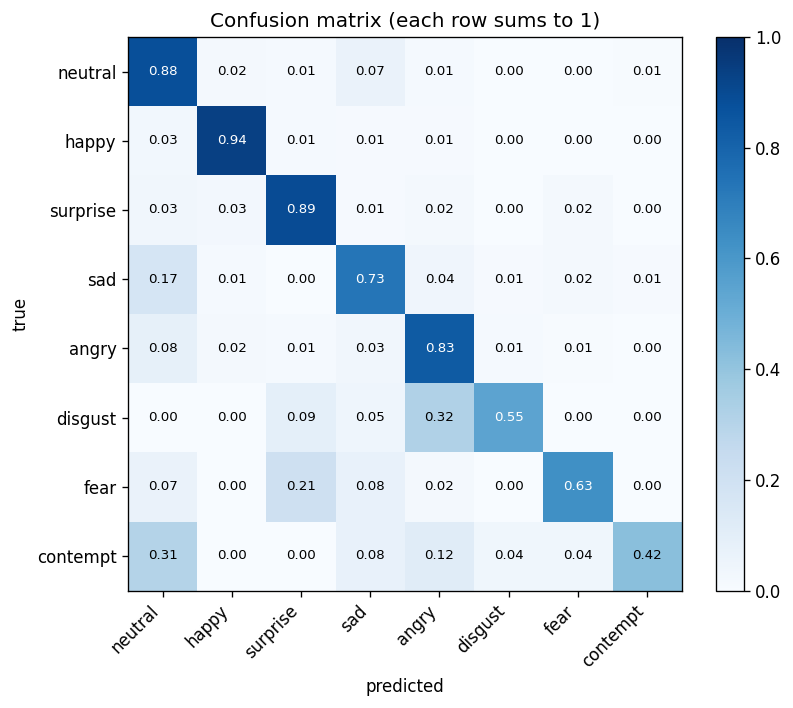

,run,test macro-F1,test accuracy,best epoch,epochs run
0,resnet18_small_ferplus_majority_48px_sqrt_inverse,0.7356,0.8611,21,25
1,facenet_ferplus_majority_160px_sqrt_inverse,0.7303,0.8611,20,25
2,resnet18_ferplus_majority_128px_sqrt_inverse_e...,0.7293,0.8626,45,60
3,resnet18_ferplus_majority_128px_sqrt_inverse,0.7277,0.8560,24,25
4,alexnet_ferplus_majority_128px_sqrt_inverse_e30,0.6963,0.8276,25,30
5,resnet18_ferplus_majority_128px_sqrt_inverse_s...,0.6849,0.8232,25,25


In [7]:
show('resnet18_small_ferplus_majority_48px_sqrt_inverse')
results()

## Exercise 3: improve on the baseline · Partner A

**Published results to compare with (accuracy; please double-check the numbers on Papers with Code before putting them in your report):**

*FER2013, original 7-class labels:*
* Khaireddin & Chen 2021, VGGNet variant, single network: about **73.3%** (often cited as best single network)
* Pramerdorfer & Kampel 2016, ensemble of CNNs: about **75.2%**
* Pham et al. 2020, Residual Masking Network ensemble: about **76.8%**
* Human accuracy on FER2013 is estimated at about 65 ± 5% (Goodfellow et al. 2013)

*FER+ labels (what this code uses, 8 classes):*
* Barsoum et al. 2016 (the FER+ paper), VGG-13: about **83.9%** (majority vote) / **85.0%** (label distribution)
* Recent methods (e.g. TransFER, ICCV 2021, with face-pretrained backbones) reach about **90–91%**

Our numbers are on FER+ labels, so compare with the FER+ results, not the 73–77% FER2013 ones.

**Proposed method (one run, all three ideas combined):**
* **Longer training: 60 epochs** with the same one-cycle schedule. 25 epochs stops while the model is still improving; with more epochs the learning rate decays more slowly.
* **Mixup (α=0.2) + CutMix (α=1.0)** on 50% of batches. Mixup blends two faces and their labels; CutMix pastes a patch of one face into another. Both regularize the network (it can't memorise individual noisy images) and make predictions less over-confident. This matters because FER labels are noisy and the classes overlap.
* **EMA of the weights (decay 0.999)**: the model used for validation/testing is a running average of the weights over roughly the last 1000 steps. This averages out the noise of the last updates and usually adds a fraction of a point to a point.

Mixup/CutMix make the training loss higher (the targets are mixed), so compare **validation** curves, not training loss.

In [ ]:
!python train.py --data-dir $DATA --out-dir $RUNS --epochs 60 --mixup 0.2 --cutmix 1.0 --ema 0.999

Device: Tesla T4
Found FER2013 (csv) at /content/data/fer2013/fer2013.csv
  train:  26940 images
  val  :   3396 images
  test :   3376 images
Run folder: /content/drive/MyDrive/fer_runs/resnet18_ferplus_majority_128px_sqrt_inverse_e60_mixup0.2_cutmix1_ema0.999
resnet18: 11.2M parameters
          images  loss weight
neutral     9365         0.70
happy       7410         0.78
surprise    3378         1.16
sad         3403         1.16
angry       2399         1.38
disgust      175         5.09
fear         648         2.65
contempt     162         5.30
epoch  1/60 | train loss 2.298 | val loss 1.877 | val acc 0.626 | val macro-F1 0.385 | 16s  <- best
epoch  2/60 | train loss 1.982 | val loss 1.654 | val acc 0.722 | val macro-F1 0.495 | 16s  <- best
epoch  3/60 | train loss 1.809 | val loss 1.505 | val acc 0.769 | val macro-F1 0.600 | 18s  <- best
epoch  4/60 | train loss 1.761 | val loss 1.421 | val acc 0.803 | val macro-F1 0.648 | 19s  <- best
epoch  5/60 | train loss 1.711 | val loss

learning_curves


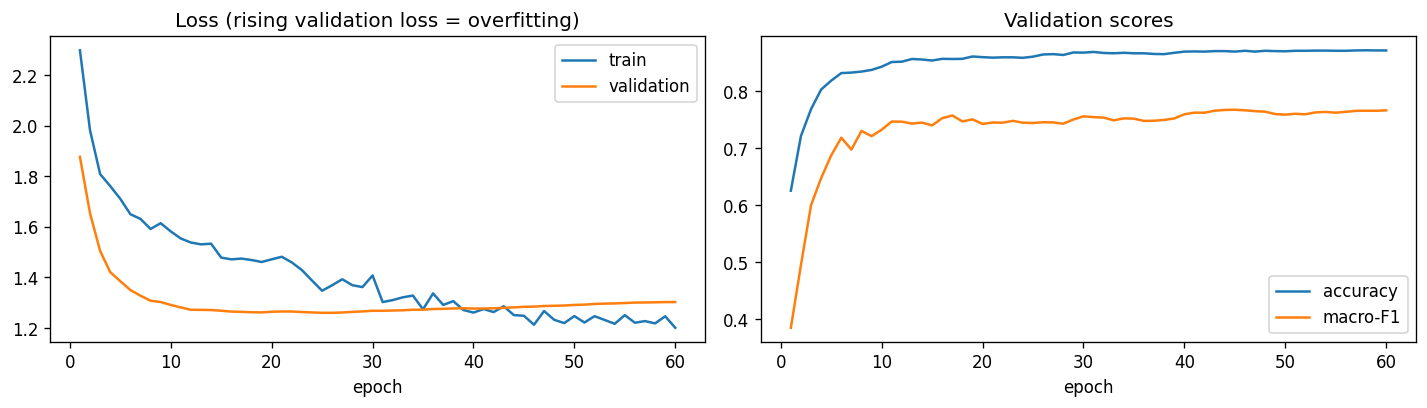

confusion_matrix


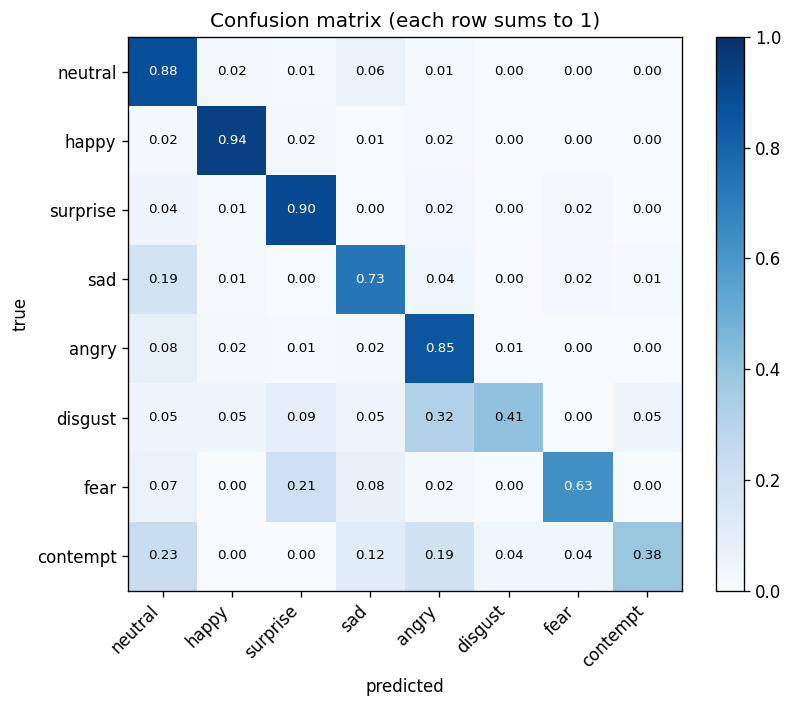

,run,test macro-F1,test accuracy,best epoch,epochs run
0,resnet18_small_ferplus_majority_48px_sqrt_inverse,0.7356,0.8611,21,25
1,resnet18_ferplus_majority_128px_sqrt_inverse_e...,0.7293,0.8626,45,60
2,resnet18_ferplus_majority_128px_sqrt_inverse,0.7277,0.8560,24,25


In [ ]:
show('resnet18_ferplus_majority_128px_sqrt_inverse_e60_mixup0.2_cutmix1_ema0.999')
results()

*Optional, if you have time:* try one learning-rate change on top, e.g. `--lr 1e-3` or `--lr 3e-4` (add `--tag lr1e-3` so it gets its own folder), or the same recipe on the best model from Ex 4d.

In [ ]:
# optional
# !python train.py --data-dir $DATA --out-dir $RUNS --epochs 60 --mixup 0.2 --cutmix 1.0 --ema 0.999 --lr 1e-3 --tag lr1e-3

## Exercise 4a: ResNet-18 without pretraining (random init) · Partner B

In [ ]:
!python train.py --data-dir $DATA --out-dir $RUNS --no-pretrained

Device: Tesla T4
Found FER2013 (csv) at /content/data/fer2013/fer2013.csv
  train:  26940 images
  val  :   3396 images
  test :   3376 images
Run folder: /content/drive/MyDrive/fer_runs/resnet18_ferplus_majority_128px_sqrt_inverse_scratch
resnet18: 11.2M parameters
          images  loss weight
neutral     9365         0.70
happy       7410         0.78
surprise    3378         1.16
sad         3403         1.16
angry       2399         1.38
disgust      175         5.09
fear         648         2.65
contempt     162         5.30
epoch  1/25 | train loss 2.320 | val loss 2.193 | val acc 0.412 | val macro-F1 0.203 | 15s  <- best
epoch  2/25 | train loss 2.173 | val loss 1.999 | val acc 0.536 | val macro-F1 0.297 | 15s  <- best
epoch  3/25 | train loss 1.969 | val loss 1.867 | val acc 0.534 | val macro-F1 0.374 | 17s  <- best
epoch  4/25 | train loss 1.835 | val loss 1.842 | val acc 0.597 | val macro-F1 0.411 | 17s  <- best
epoch  5/25 | train loss 1.740 | val loss 1.617 | val acc 0.731

learning_curves


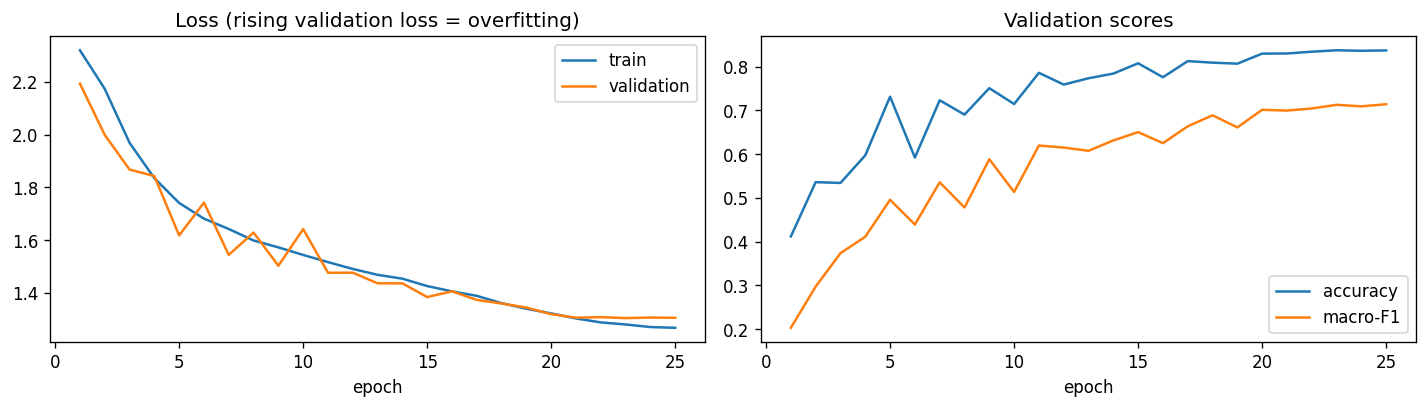

confusion_matrix


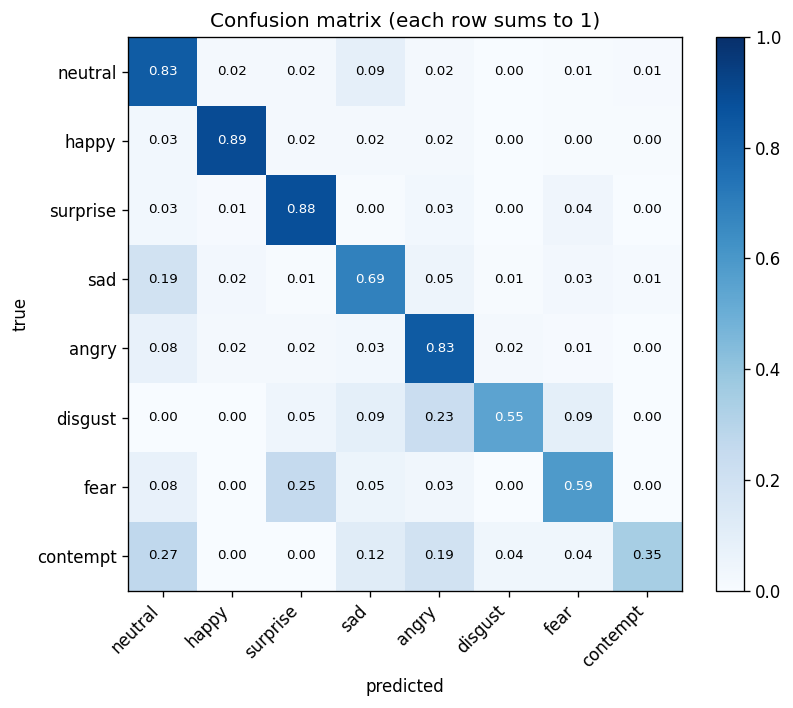

In [ ]:
show('resnet18_ferplus_majority_128px_sqrt_inverse_scratch')

## Exercise 4b: AlexNet (the AffectNet paper's network) · Partner B

In [ ]:
!python train.py --data-dir $DATA --out-dir $RUNS --model alexnet --epochs 30

Device: Tesla T4
Found FER2013 (csv) at /content/data/fer2013/fer2013.csv
  train:  26940 images
  val  :   3396 images
  test :   3376 images
Run folder: /content/drive/MyDrive/fer_runs/alexnet_ferplus_majority_128px_sqrt_inverse_e30
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth
100% 233M/233M [00:01<00:00, 146MB/s]
alexnet: 57.0M parameters
          images  loss weight
neutral     9365         0.70
happy       7410         0.78
surprise    3378         1.16
sad         3403         1.16
angry       2399         1.38
disgust      175         5.09
fear         648         2.65
contempt     162         5.30
/content/fer_project/train.py:110: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the f

learning_curves


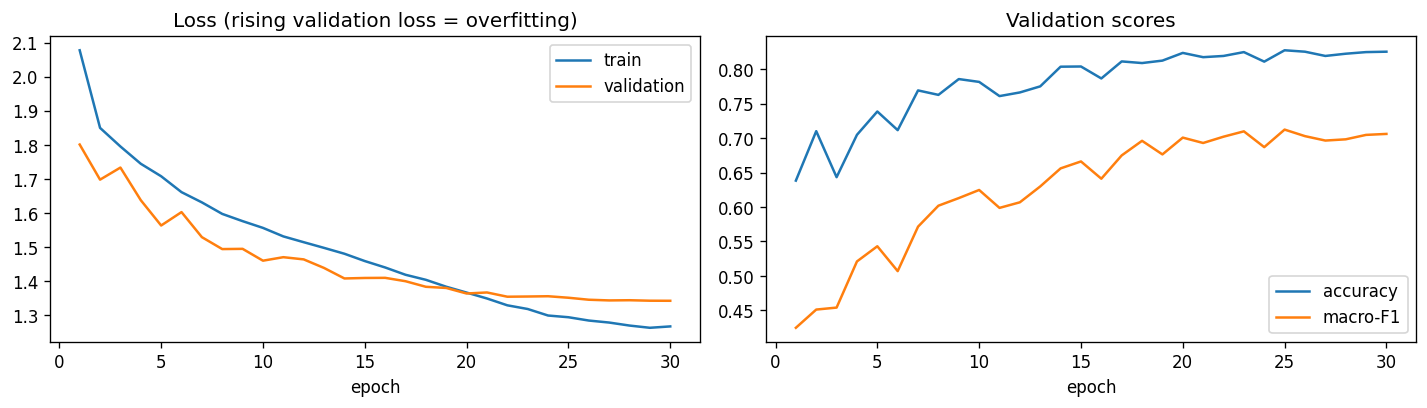

confusion_matrix


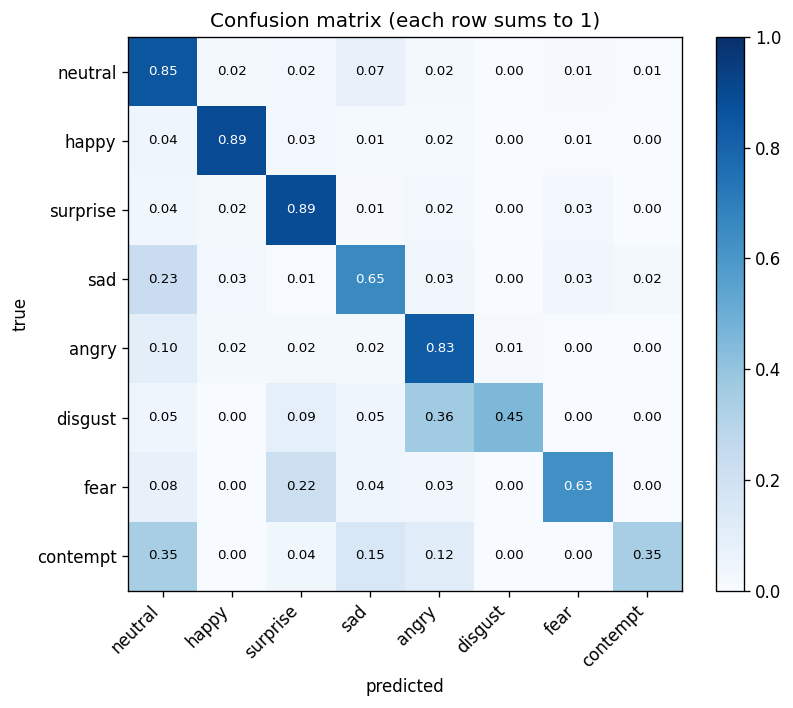

In [ ]:
show('alexnet_ferplus_majority_128px_sqrt_inverse_e30')

## Exercise 4c: AlexNet vs ResNet-18 during training · Partner B

Needs the Ex 1 and Ex 4b runs. (AlexNet ran 30 epochs and ResNet 25; the one-cycle schedule is stretched to each, so compare shapes and best values.)

Things to look at when explaining the difference:
* **Train vs val loss gap**: AlexNet has about 57M parameters, almost all in its big fully connected layers, and no BatchNorm; ResNet-18 has about 11M and uses global average pooling. Which one overfits more?
* **Speed of convergence / stability**: BatchNorm and residual connections make ResNet easier to optimize; AlexNet often learns more slowly or more noisily.
* **First layer**: AlexNet's 11×11 stride-4 conv throws away fine detail (mouth corners, eyebrows) on a face that was only 48 px to begin with.
* **Macro-F1 vs accuracy**: are the rare classes (disgust, contempt, fear) learned at all? Look at the confusion matrices.

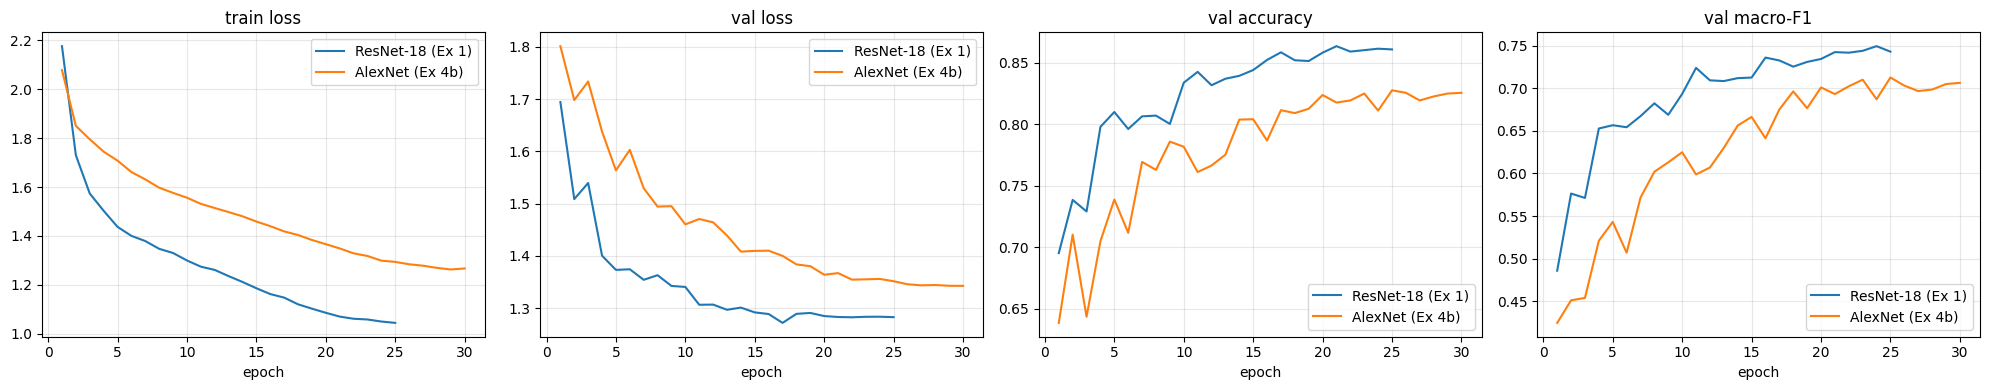

ResNet-18 (Ex 1)   best val F1 0.749 (epoch 24), val acc 0.862, final train loss 1.045, final val loss 1.283
AlexNet (Ex 4b)    best val F1 0.713 (epoch 25), val acc 0.828, final train loss 1.267, final val loss 1.342


In [ ]:
import matplotlib.pyplot as plt
pairs = {'ResNet-18 (Ex 1)': BASE, 'AlexNet (Ex 4b)': 'alexnet_ferplus_majority_128px_sqrt_inverse_e30'}
# add more runs to the plot if you like, e.g. 'ResNet-18 scratch (Ex 4a)': BASE + '_scratch'
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for label, run in pairs.items():
    h = pd.read_csv(f'{RUNS}/{run}/history.csv')
    for ax, col, title in zip(axes, ['train_loss', 'val_loss', 'accuracy', 'macro_f1'],
                              ['train loss', 'val loss', 'val accuracy', 'val macro-F1']):
        ax.plot(h.epoch, h[col], label=label); ax.set_title(title); ax.set_xlabel('epoch')
for ax in axes: ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{RUNS}/ex4c_alexnet_vs_resnet18.png', dpi=120); plt.show()

for label, run in pairs.items():
    h = pd.read_csv(f'{RUNS}/{run}/history.csv')
    best = h.loc[h.macro_f1.idxmax()]
    print(f"{label:18s} best val F1 {best.macro_f1:.3f} (epoch {int(best.epoch)}), val acc {best.accuracy:.3f}, "
          f"final train loss {h.train_loss.iloc[-1]:.3f}, final val loss {h.val_loss.iloc[-1]:.3f}")

## Exercise 4d: a network pretrained on faces · Partner B

**Choice: Inception-ResNet-v1 trained on VGGFace2** (`facenet-pytorch`, `--model facenet`).
* VGGFace2 is a **face recognition** dataset: about 3.3M photos of 9,131 people, with large variation in pose, age, lighting and expression. To tell people apart, the network had to learn detailed facial features (eyes, brows, mouth, face shape) and to align on faces, which ImageNet weights never learned.
* It is *not* trained on FER2013, so there is no risk that test images were seen during pretraining (some expression models on Hugging Face were trained on FER2013 including its test split, which would make the comparison unfair).
* Its native input is 160×160, so we use `--img-size 160`. The wrapper in `models.py` converts our ImageNet normalization to FaceNet's `(x − 127.5)/128`.

Caveat for your discussion: identity features are partly designed to be **invariant** to expression (the same person smiling or frowning should get the same embedding), so the deeper layers may need more fine-tuning than the early ones.

In [ ]:
!python train.py --data-dir $DATA --out-dir $RUNS --model facenet --img-size 160

Device: Tesla T4
Found FER2013 (csv) at /content/data/fer2013/fer2013.csv
  train:  26940 images
  val  :   3396 images
  test :   3376 images
Run folder: /content/drive/MyDrive/fer_runs/facenet_ferplus_majority_160px_sqrt_inverse
100% 107M/107M [00:04<00:00, 25.4MB/s]
facenet: 23.5M parameters
          images  loss weight
neutral     9365         0.70
happy       7410         0.78
surprise    3378         1.16
sad         3403         1.16
angry       2399         1.38
disgust      175         5.09
fear         648         2.65
contempt     162         5.30
epoch  1/25 | train loss 1.686 | val loss 1.392 | val acc 0.824 | val macro-F1 0.652 | 52s  <- best
epoch  2/25 | train loss 1.475 | val loss 1.457 | val acc 0.776 | val macro-F1 0.595 | 54s
epoch  3/25 | train loss 1.475 | val loss 1.418 | val acc 0.790 | val macro-F1 0.622 | 58s
epoch  4/25 | train loss 1.448 | val loss 1.347 | val acc 0.819 | val macro-F1 0.680 | 62s  <- best
epoch  5/25 | train loss 1.413 | val loss 1.410 | va

learning_curves


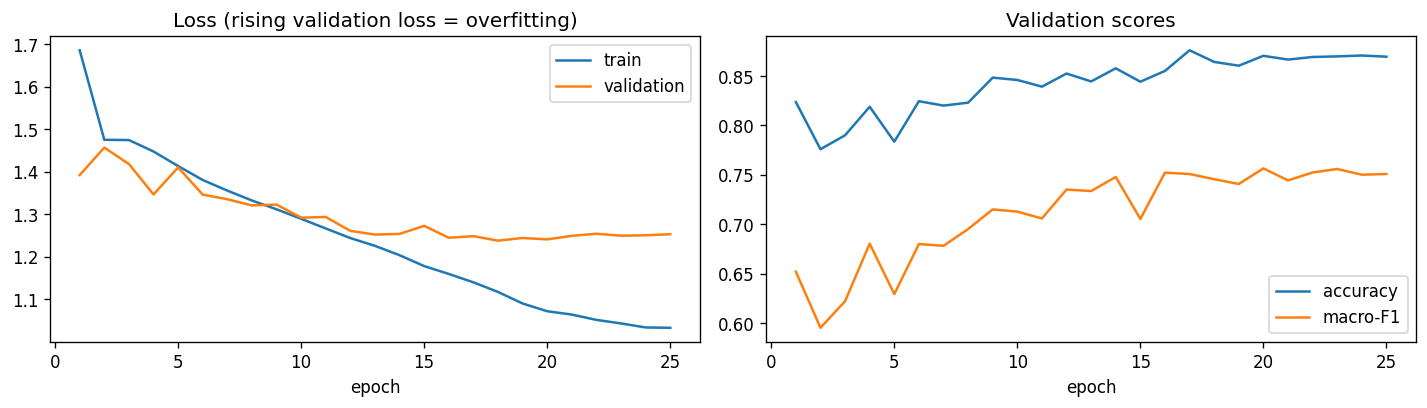

confusion_matrix


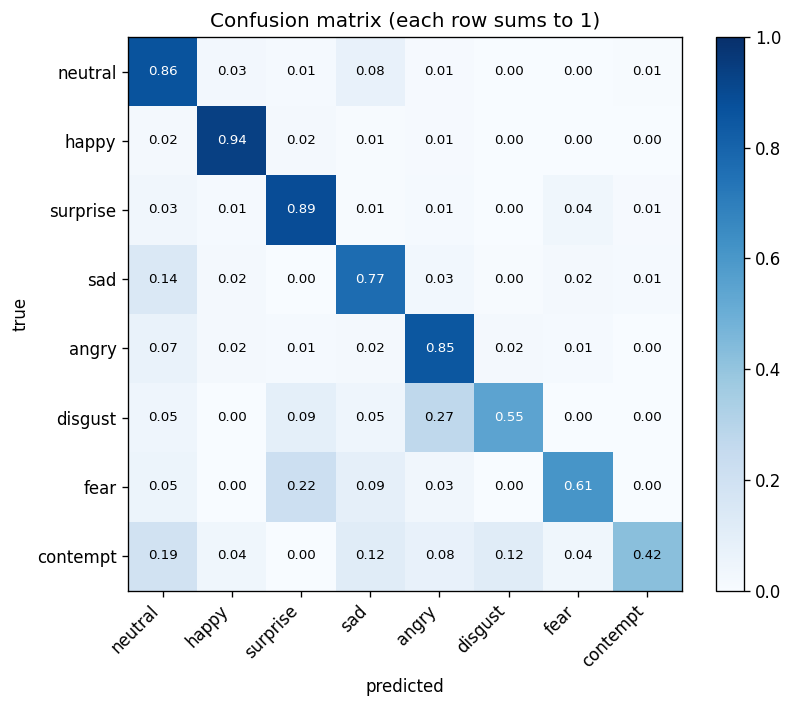

,run,test macro-F1,test accuracy,best epoch,epochs run
0,resnet18_small_ferplus_majority_48px_sqrt_inverse,0.7356,0.8611,21,25
1,facenet_ferplus_majority_160px_sqrt_inverse,0.7303,0.8611,20,25
2,resnet18_ferplus_majority_128px_sqrt_inverse_e...,0.7293,0.8626,45,60
3,resnet18_ferplus_majority_128px_sqrt_inverse,0.7277,0.8560,24,25
4,alexnet_ferplus_majority_128px_sqrt_inverse_e30,0.6963,0.8276,25,30
5,resnet18_ferplus_majority_128px_sqrt_inverse_s...,0.6849,0.8232,25,25


In [8]:
show('facenet_ferplus_majority_160px_sqrt_inverse')
results()

*Optional:* combine the face-pretrained model with the Ex 3 recipe (this might be your best model overall):

In [ ]:
# !python train.py --data-dir $DATA --out-dir $RUNS --model facenet --img-size 160 --epochs 60 --mixup 0.2 --cutmix 1.0 --ema 0.999

## Summary: every finished run (for the report)

Sorted by test macro-F1. Copy this table into your report and compare each exercise with the Ex 1 baseline.

## Exercise 5: your own photos

1. In Google Drive, open `My Drive/fer_runs/` and create a folder called **`photos`**.
2. Put your photos in it. Any name works, but descriptive names make the output easy to read, e.g. `alex_happy.jpg`, `alex_surprise.jpg`, `partner_sad.png` (no spaces). JPG, PNG and iPhone HEIC are all fine (HEIC is converted automatically).
3. Use front-facing, well-lit photos with one face each.
4. Run the cell below. It uses the run with the best test macro-F1 (or set `BEST` yourself) and saves the annotated images plus a `predictions.txt` to `My Drive/fer_runs/ex5_predictions/`.

Using model: resnet18_small_ferplus_majority_48px_sqrt_inverse
Device: Tesla T4
/content/photos/alex_angry.png
  neutral   79.7%
  disgust   6.2%
  contempt  5.5%
  saved /content/photos/alex_angry_prediction.png
/content/photos/alex_happy.png
  happy     81.8%
  contempt  5.3%
  disgust   5.2%
  saved /content/photos/alex_happy_prediction.png
/content/photos/alex_sad.png
  neutral   77.5%
  contempt  6.7%
  disgust   6.4%
  saved /content/photos/alex_sad_prediction.png
/content/photos/aryan_angry.png
  neutral   74.4%
  disgust   8.6%
  contempt  6.9%
  saved /content/photos/aryan_angry_prediction.png
/content/photos/aryan_happy.png
  happy     79.9%
  contempt  5.9%
  disgust   5.7%
  saved /content/photos/aryan_happy_prediction.png
/content/photos/aryan_sad.png
  no face found (or face detector unavailable), using the whole image
  neutral   66.7%
  happy     14.0%
  contempt  7.2%
  saved /content/photos/aryan_sad_prediction.png
 libpng warning: iCCP: extra compressed data
libpng w

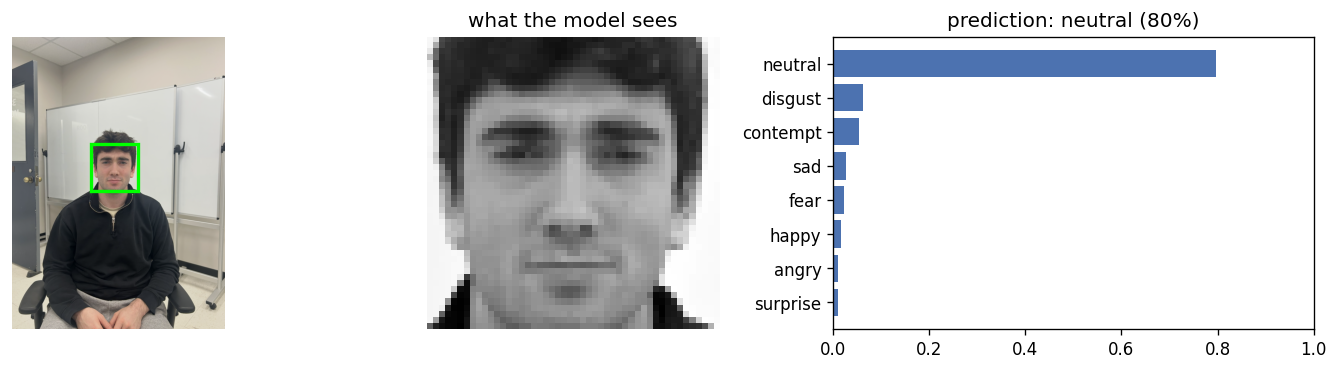

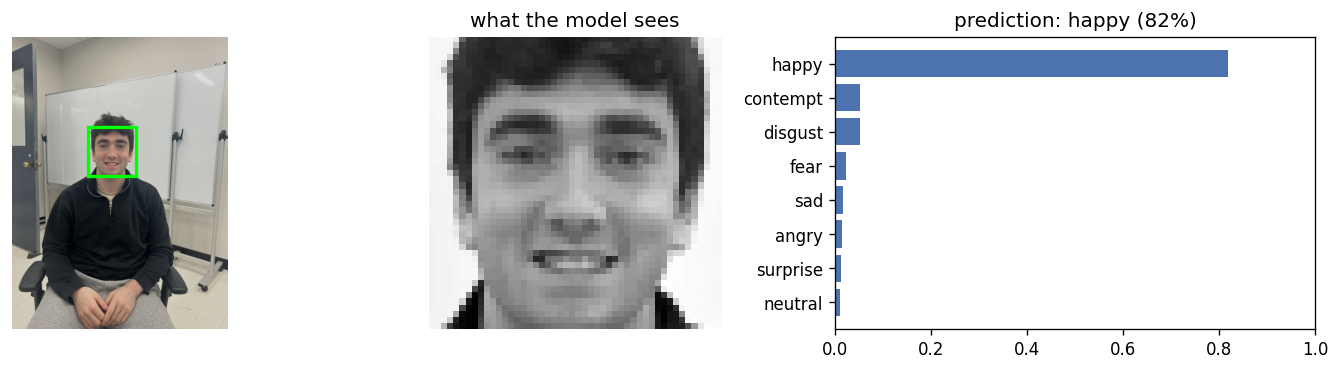

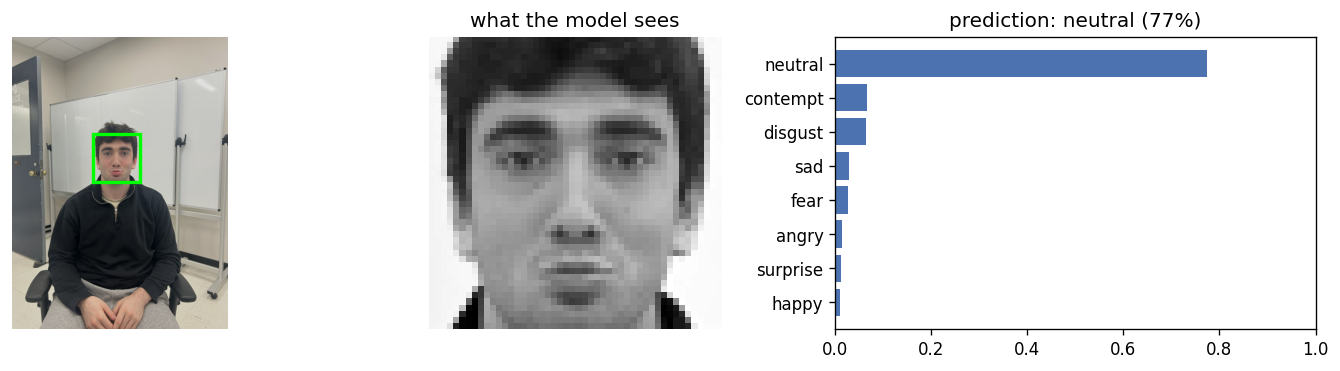

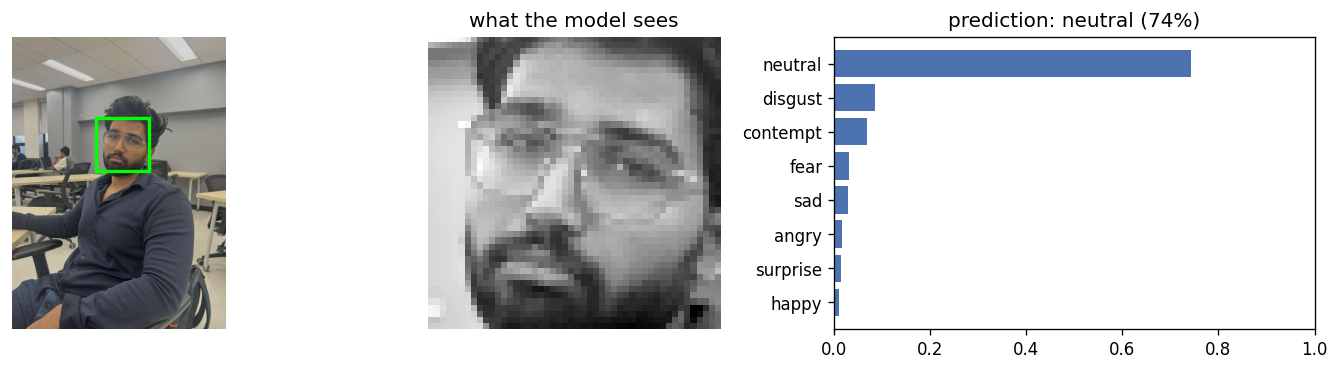

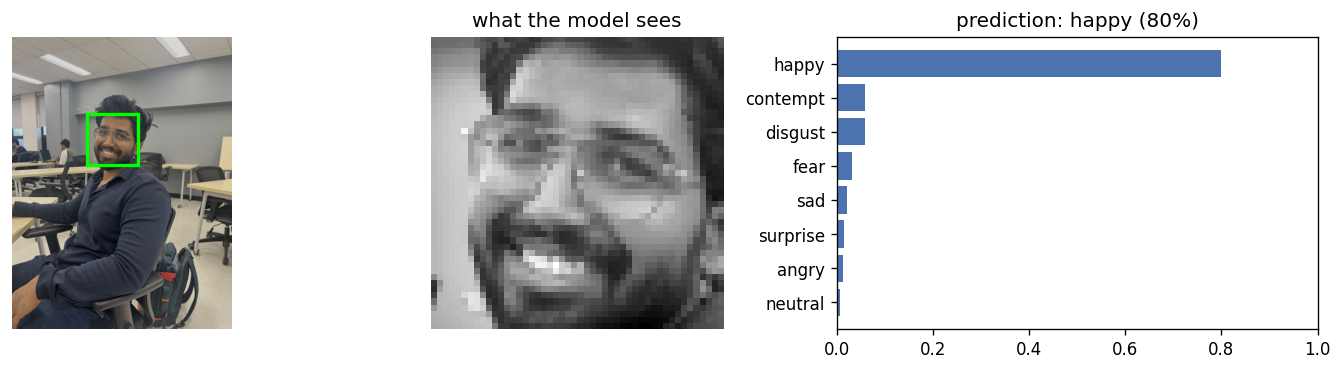

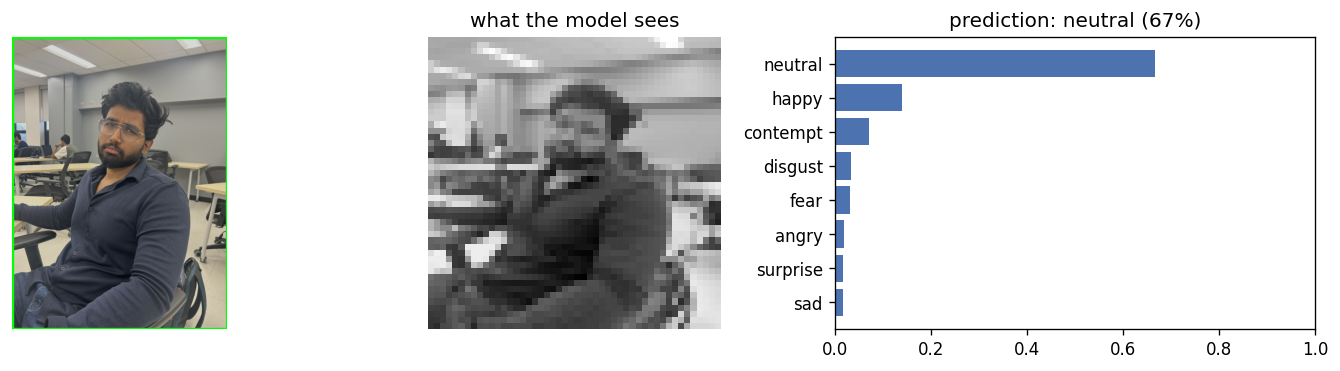

Saved to /content/drive/MyDrive/fer_runs/ex5_predictions


In [9]:
import shutil, subprocess
PHOTOS_IN = f'{RUNS}/photos'                 # put your photos here in Drive
PHOTOS_OUT = f'{RUNS}/ex5_predictions'        # results are saved here
BEST = results().loc[0, 'run']                # or e.g. BEST = 'facenet_ferplus_majority_160px_sqrt_inverse'
print('Using model:', BEST)

# copy the photos to the Colab machine (converting HEIC to JPG) and predict there
WORK = '/content/photos'
shutil.rmtree(WORK, ignore_errors=True); os.makedirs(WORK)
files = sorted(f for f in glob.glob(f'{PHOTOS_IN}/*') if f.lower().endswith(('.jpg', '.jpeg', '.png', '.heic', '.heif')))
if not files:
    raise SystemExit(f'No photos found in {PHOTOS_IN}: create the folder in Drive and put .jpg/.png/.heic files in it')
if any(f.lower().endswith(('.heic', '.heif')) for f in files):
    subprocess.run(['pip', 'install', '-q', 'pillow-heif'], check=True)
    import pillow_heif; pillow_heif.register_heif_opener()
from PIL import Image as PILImage, ImageOps
for f in files:
    name = os.path.splitext(os.path.basename(f))[0].replace(' ', '_')
    if f.lower().endswith(('.heic', '.heif')):
        ImageOps.exif_transpose(PILImage.open(f)).convert('RGB').save(f'{WORK}/{name}.jpg', quality=95)
    else:
        ImageOps.exif_transpose(PILImage.open(f)).convert('RGB').save(f'{WORK}/{name}{os.path.splitext(f)[1].lower()}')
inputs = sorted(glob.glob(f'{WORK}/*'))

out = subprocess.run(['python', 'predict.py', '--checkpoint', f'{RUNS}/{BEST}/best.pt', *inputs],
                     capture_output=True, text=True)
print(out.stdout, out.stderr[-2000:])

os.makedirs(PHOTOS_OUT, exist_ok=True)
with open(f'{PHOTOS_OUT}/predictions.txt', 'w') as fh:
    fh.write(f'Model: {BEST}\n\n' + out.stdout)
for f in sorted(glob.glob(f'{WORK}/*_prediction.png')):
    shutil.copy(f, PHOTOS_OUT)
    display(Image(f))
print('Saved to', PHOTOS_OUT)